# Assignment 08:<br> RNNs, LSTMs and sequence-to-sequence translation
**Schwartzberg, Paul**

Problems 1 and 2 use Microsoft opening prices to compare recurrent forecasting models.<br>
Problem 3 compares the supplied English-to-Spanish translator with vocabulary budgets of 1,000 and 3,000 tokens.<br>
The notebook contains the code, figures, measured results and explanations for all three problems.

I ran the cells in order in a Colab GPU runtime.<br><br>
The first run downloads the small data files; running the training cells trains the models again.<br>
The stock experiments retain 100 epochs per model, and each translator retains 10 epochs.

## Setup and data sources

I use the supplied PyTorch implementations and save reloadable PyTorch checkpoints.<br>
Seed 42 controls the data splits, initial weights and shuffled training batches.<br>
Results can still differ between devices and software versions, so I record the environment used for this run.

The Microsoft data were downloaded from Yahoo Finance on October 27th 2026.<br><br>
I use its daily `Open` field directly, without applying dividend adjustments.<br>
The repository keeps the provider response, the requested periods and file checksums.<br>
This notebook retrieves that saved copy when the local files are missing.

In [1]:
# Import the numerical tools and install only a missing helper library.
import importlib.util
import subprocess
import sys
for module, package in [("numpy", "numpy"), ("pandas", "pandas"),
                        ("matplotlib", "matplotlib"), ("sklearn", "scikit-learn")]:
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import copy
import gc
import hashlib
import json
import math
import platform
import random
import re
import time
import unicodedata
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from IPython.display import display, Markdown

get_ipython().run_line_magic("matplotlib", "inline")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(4)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

def save_figure(fig, filename):
    """Keep each figure on disk and embed it in the notebook output."""
    fig.savefig(FIGURE_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

environment = {"python": platform.python_version(), "torch": torch.__version__,
               "numpy": np.__version__, "pandas": pd.__version__, "seed": SEED,
               "device": str(device),
               "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else None}
(OUTPUT_DIR / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")
print(environment)

{'python': '3.13.16', 'torch': '2.11.0+cu130', 'numpy': '2.1.3', 'pandas': '2.2.3', 'seed': 42, 'device': 'cuda', 'gpu': 'Tesla T4'}


In [2]:
# Retrieve the exact Microsoft data snapshot if this notebook is opened on its own.
STOCK_DATA_COMMIT = "29a161691055455a1fccfa5b03dadb07dcba13c6"
STOCK_DATA_BASE = f"https://raw.githubusercontent.com/schwartzberg/dec08c/{STOCK_DATA_COMMIT}/data/"
stock_file_checksums = {
    "MSFT_all.csv": "ba6c8d2c4f33d1aa7b9e0d1e8d75231e3a868067752e1c95d5b9bccc2712ff68",
    "MSFT_development.csv": "694bf16d174118e12d58ee77eff27c595556ad7cbd564db12e282fd916b96f37",
    "MSFT_test.csv": "499eb5077c8078e9469129249beb857e2bfa8608d4f1f5aee0f2f0f3137a468c",
    "MSFT_yahoo_raw.json": "5a682a7a774760cdddcee3ad2d510bbe16352c3920cfa0578781f516eaf51b57",
}
for filename, expected_hash in stock_file_checksums.items():
    path = DATA_DIR / filename
    if not path.exists():
        urllib.request.urlretrieve(STOCK_DATA_BASE + filename, path)
    assert hashlib.sha256(path.read_bytes()).hexdigest() == expected_hash, filename
provenance_path = DATA_DIR / "MSFT_provenance.json"
if not provenance_path.exists():
    urllib.request.urlretrieve(STOCK_DATA_BASE + provenance_path.name, provenance_path)
stock_provenance = json.loads(provenance_path.read_text(encoding="utf-8"))
assert stock_provenance["symbol"] == "MSFT"
assert stock_provenance["raw_sha256"] == stock_file_checksums["MSFT_yahoo_raw.json"]
print("Provider:", stock_provenance["provider"], "| downloaded:", stock_provenance["retrieved_utc"])
print("Verified four data-file checksums. The source response is retained for checking.")

Provider: Yahoo Finance | downloaded: 2026-10-27T13:39:40.163945+00:00
Verified four data-file checksums. The source response is retained for checking.


## Problem 1. Predict Microsoft's opening prices

I use Microsoft (`MSFT`) in place of Apple.<br>
The development period starts in January 2016 and ends on September 6th 2026.<br>
The test period runs from September 9th to October 10th 2026.<br>
These are calendar limits; the tables below show the trading dates actually present in the downloaded data.

Both supplied notebooks use PyTorch.<br>
I retain their four recurrent layers, 50 hidden units per layer, dropout of 0.20, Adam learning rate of 0.001, batch size of 32 and 100 training epochs.<br>
The RNN also retains gradient clipping at a norm of 1.0.<br>
The first experiment uses the original 60-observation input and predicts one opening price.<br>
I save the learned weights with `torch.save`, the PyTorch equivalent of saving a trained Keras model, and check the restored predictions.

Development: 2684 rows; 2016-01-04 to 2026-09-04
Test: 23 rows; 2026-09-09 to 2026-10-09
Context-only dates: ['2026-09-08']


,Date,Open
0,2016-01-04,54.32
1,2016-01-05,54.93
2,2016-01-06,54.32


,Date,Open
0,2026-09-09,493.070007
1,2026-09-10,488.320007
2,2026-09-11,495.649994


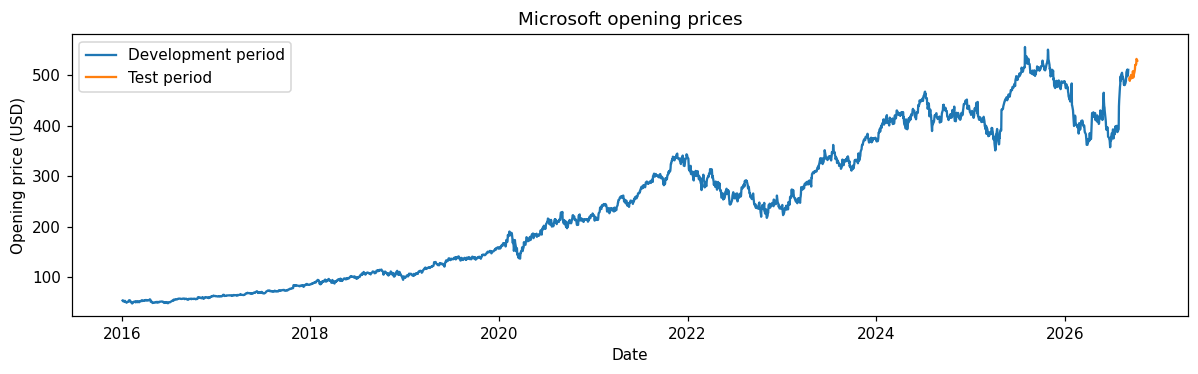

In [3]:
# Load the two requested periods and retain any observed gap day as context.
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import TensorDataset, DataLoader
import time
import json
import gc

STOCK_DIR = OUTPUT_DIR / "stocks"
STOCK_DIR.mkdir(parents=True, exist_ok=True)
STOCK_EPOCHS = 100
STOCK_BATCH_SIZE = 32
STOCK_LEARNING_RATE = 0.001
# Enable only to recover completed runs after an interrupted execution.
# A fresh, complete submission run leaves this False.
STOCK_REUSE_COMPLETED = False

def stock_load_prices(path):
    frame = pd.read_csv(path)
    assert {"Date", "Open"}.issubset(frame.columns), path
    frame = frame[["Date", "Open"]].copy()
    frame["Date"] = pd.to_datetime(frame["Date"], errors="raise")
    frame["Open"] = pd.to_numeric(frame["Open"], errors="raise")
    frame = frame.sort_values("Date").reset_index(drop=True)
    assert len(frame) and not frame["Date"].duplicated().any()
    assert np.isfinite(frame["Open"]).all() and (frame["Open"] > 0).all()
    return frame

stock_development = stock_load_prices(DATA_DIR / "MSFT_development.csv")
stock_test = stock_load_prices(DATA_DIR / "MSFT_test.csv")
if (DATA_DIR / "MSFT_all.csv").exists():
    stock_all = stock_load_prices(DATA_DIR / "MSFT_all.csv")
    stock_all = stock_all.loc[
        stock_all["Date"].between(stock_development["Date"].min(), stock_test["Date"].max())
    ].reset_index(drop=True)
else:
    stock_all = pd.concat([stock_development, stock_test], ignore_index=True)
assert stock_development["Date"].min() >= pd.Timestamp("2016-01-01")
assert stock_development["Date"].max() <= pd.Timestamp("2026-09-06")
assert stock_test["Date"].min() >= pd.Timestamp("2026-09-09")
assert stock_test["Date"].max() <= pd.Timestamp("2026-10-10")
assert stock_development["Date"].max() < stock_test["Date"].min()
stock_development_count = len(stock_development)
assert stock_development_count > 120 and len(stock_test) >= 5
pd.testing.assert_frame_equal(
    stock_all.iloc[:stock_development_count].reset_index(drop=True), stock_development,
    check_dtype=False)
stock_dates = pd.DatetimeIndex(stock_all["Date"])
stock_raw = stock_all[["Open"]].to_numpy(dtype=np.float32)
stock_test_positions = stock_dates.get_indexer(stock_test["Date"])
assert (stock_test_positions >= stock_development_count).all()
np.testing.assert_allclose(stock_raw[stock_test_positions, 0], stock_test["Open"].to_numpy())
stock_test_position_set = set(stock_test_positions.tolist())
stock_context_only_positions = [i for i in range(stock_development_count, len(stock_all))
                          if i not in stock_test_position_set]
print("Development:", len(stock_development), "rows;",
      stock_development["Date"].min().date(), "to", stock_development["Date"].max().date())
print("Test:", len(stock_test), "rows;",
      stock_test["Date"].min().date(), "to", stock_test["Date"].max().date())
print("Context-only dates:", [stock_dates[i].strftime("%Y-%m-%d") for i in stock_context_only_positions])
display(stock_development.head(3))
display(stock_test.head(3))

# September 6th is a Sunday; September 7th is the US Labor Day holiday.
# If present, September 8th is used only as known input before September 9th.
# It is never used to fit a scaler or as a training, validation or test target.
stock_period_figure, stock_period_axis = plt.subplots(figsize=(11, 3.5))
stock_period_axis.plot(stock_development["Date"], stock_development["Open"], label="Development period")
stock_period_axis.plot(stock_test["Date"], stock_test["Open"], label="Test period")
stock_period_axis.set(title="Microsoft opening prices", xlabel="Date", ylabel="Opening price (USD)")
stock_period_axis.legend()
stock_period_figure.tight_layout()
save_figure(stock_period_figure, "stock_price_periods.png")

### Model, windows and saved weights

An input window contains only observations available before its target date.<br>
Each recurrent layer passes its sequence to the next layer and the fourth layer's final time step feeds the output layer.<br>
A one-step model has one output, while the five-step model below has five outputs.<br>
Hidden states start at zero for each window, as in the supplied notebooks.

Training minimises mean squared error on scaled prices.<br>
Each batch starts with cleared gradients.<br>
Back-propagation calculates the gradients, and Adam uses them to update the weights.<br>
The RNN's gradient clipping acts before the update.<br>
Evaluation disables dropout and gradient tracking.

Test evaluation rolls forward through the observed prices.<br>
Later test forecasts can therefore use earlier test opening prices as inputs, while the weights remain fixed.<br>
This evaluates forecasts made as each new observation arrives.<br>
The persistence baseline repeats the most recent observed opening price.<br>
Errors are reported in dollars after reversing the training scale.

In [4]:
# These helpers are shared by all RNN and LSTM experiments.
class StockSequenceModel(nn.Module):
    def __init__(self, kind, horizon=1, hidden_size=50, dropout=0.20):
        super().__init__()
        if kind not in {"RNN", "LSTM"}:
            raise ValueError(kind)
        self.kind = kind
        recurrent = nn.RNN if kind == "RNN" else nn.LSTM
        self.layers = nn.ModuleList([
            recurrent(1 if number == 0 else hidden_size, hidden_size,
                      num_layers=1, batch_first=True)
            for number in range(4)])
        self.dropouts = nn.ModuleList([nn.Dropout(dropout) for _ in range(4)])
        self.output = nn.Linear(hidden_size, horizon)

    def forward(self, values):
        for number, layer in enumerate(self.layers):
            values, _ = layer(values)
            if number == 3:
                values = values[:, -1, :]
            values = self.dropouts[number](values)
        return self.output(values)

def stock_windows(scaled, origins, lookback, horizon):
    """Origin i predicts rows i through i+horizon-1 from rows i-lookback:i."""
    origins = np.asarray(origins, dtype=np.int64)
    assert origins.ndim == 1 and len(origins)
    assert origins.min() >= lookback and origins.max() + horizon <= len(scaled)
    inputs = np.stack([scaled[i - lookback:i] for i in origins]).astype(np.float32)
    targets = np.stack([scaled[i:i + horizon, 0] for i in origins]).astype(np.float32)
    assert inputs.shape == (len(origins), lookback, 1)
    assert targets.shape == (len(origins), horizon)
    return inputs, targets

def stock_test_origins(horizon):
    # Every future target must belong to the requested test period.
    return np.array([int(i) for i in stock_test_positions
                     if all(i + h in stock_test_position_set for h in range(horizon))],
                    dtype=np.int64)

def stock_unscale(values, fitted_scaler):
    shape = np.asarray(values).shape
    return fitted_scaler.inverse_transform(np.asarray(values).reshape(-1, 1)).reshape(shape)

def stock_error_metrics(actual, predicted):
    error = np.asarray(predicted, dtype=np.float64) - np.asarray(actual, dtype=np.float64)
    assert error.shape == np.asarray(actual).shape and np.isfinite(error).all()
    return {"mae_usd": float(np.abs(error).mean()),
            "rmse_usd": float(np.sqrt(np.mean(error ** 2)))}

def stock_scaler_record(fitted_scaler):
    return {"scale_": fitted_scaler.scale_.tolist(), "min_": fitted_scaler.min_.tolist(),
            "data_min_": fitted_scaler.data_min_.tolist(),
            "data_max_": fitted_scaler.data_max_.tolist(),
            "data_range_": fitted_scaler.data_range_.tolist(),
            "n_features_in_": int(fitted_scaler.n_features_in_),
            "n_samples_seen_": int(fitted_scaler.n_samples_seen_)}

def stock_restore_scaler(record):
    fitted = MinMaxScaler()
    for key in ("scale_", "min_", "data_min_", "data_max_", "data_range_"):
        setattr(fitted, key, np.asarray(record[key], dtype=np.float32))
    fitted.n_features_in_ = record["n_features_in_"]
    fitted.n_samples_seen_ = record["n_samples_seen_"]
    return fitted

def stock_predict(model, inputs):
    model.eval()
    batches = []
    with torch.inference_mode():
        for start in range(0, len(inputs), 256):
            batch = torch.from_numpy(inputs[start:start + 256]).to(device)
            batches.append(model(batch).cpu().numpy())
    return np.concatenate(batches)

def stock_epoch(model, loader, optimizer=None):
    model.train(optimizer is not None)
    sum_squared_error, target_count = 0.0, 0
    with torch.set_grad_enabled(optimizer is not None):
        for inputs, expected in loader:
            inputs, expected = inputs.to(device), expected.to(device)
            if optimizer is not None:
                optimizer.zero_grad(set_to_none=True)
            predicted = model(inputs)
            assert predicted.shape == expected.shape
            loss = F.mse_loss(predicted, expected)
            if optimizer is not None:
                loss.backward()
                if model.kind == "RNN":
                    nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            sum_squared_error += float(F.mse_loss(
                predicted.detach(), expected, reduction="sum").item())
            target_count += expected.numel()
    return sum_squared_error / target_count

def stock_fit_model(run_name, kind, lookback, horizon, fitted_scaler,
                    train_origins, validation_origins=None):
    """Save immediately after training or whenever validation loss improves."""
    checkpoint_path = STOCK_DIR / f"{run_name}.pt"
    history_path = STOCK_DIR / f"{run_name}_history.json"
    record_path = STOCK_DIR / f"{run_name}_run.json"
    if STOCK_REUSE_COMPLETED and all(path.exists() for path in
                                     (checkpoint_path, history_path, record_path)):
        saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
        run_record = json.loads(record_path.read_text(encoding="utf-8"))
        assert run_record.get("completed") and saved["epochs"] == STOCK_EPOCHS
        assert saved["lookback"] == lookback and saved["horizon"] == horizon
        assert saved["model_config"]["kind"] == kind
        assert saved["scaler"] == stock_scaler_record(fitted_scaler)
        assert saved["training_origins"] == np.asarray(train_origins).tolist()
        expected_validation = [] if validation_origins is None else np.asarray(validation_origins).tolist()
        assert saved["validation_origins"] == expected_validation
        restored = StockSequenceModel(**saved["model_config"]).to(device)
        restored.load_state_dict(saved["model_state_dict"])
        restored.eval()
        history = json.loads(history_path.read_text(encoding="utf-8"))
        assert len(history) == STOCK_EPOCHS
        print(f"{run_name}: explicitly reusing its completed, checked checkpoint")
        return restored, run_record, history
    torch.manual_seed(SEED)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(SEED)
    scaled = fitted_scaler.transform(stock_raw).astype(np.float32)
    train_x, train_y = stock_windows(scaled, train_origins, lookback, horizon)
    train_loader = DataLoader(TensorDataset(torch.from_numpy(train_x), torch.from_numpy(train_y)),
                              batch_size=STOCK_BATCH_SIZE, shuffle=True, num_workers=0,
                              generator=torch.Generator().manual_seed(SEED))
    validation_loader = None
    if validation_origins is not None:
        val_x, val_y = stock_windows(scaled, validation_origins, lookback, horizon)
        validation_loader = DataLoader(TensorDataset(torch.from_numpy(val_x), torch.from_numpy(val_y)),
                                       batch_size=256, shuffle=False, num_workers=0)
    config = {"kind": kind, "horizon": horizon, "hidden_size": 50, "dropout": 0.20}
    model = StockSequenceModel(**config).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=STOCK_LEARNING_RATE)
    history, best_loss, selected_epoch = [], float("inf"), None
    started = time.perf_counter()
    print(f"{run_name}: inputs {train_x.shape}; targets {train_y.shape}; "
          f"parameters {sum(p.numel() for p in model.parameters()):,}")
    for epoch in range(1, STOCK_EPOCHS + 1):
        tick = time.perf_counter()
        train_mse = stock_epoch(model, train_loader, optimizer)
        val_mse = stock_epoch(model, validation_loader) if validation_loader is not None else None
        history.append({"epoch": epoch, "train_mse_scaled": train_mse,
                        "val_mse_scaled": val_mse, "seconds": time.perf_counter() - tick})
        history_path.write_text(json.dumps(history, indent=2), encoding="utf-8")
        should_save = (val_mse is not None and val_mse < best_loss) or (
            val_mse is None and epoch == STOCK_EPOCHS)
        if should_save:
            best_loss = val_mse if val_mse is not None else train_mse
            selected_epoch = epoch
            torch.save({
                "model_state_dict": {key: value.detach().cpu().clone()
                                     for key, value in model.state_dict().items()},
                "model_config": config, "lookback": lookback, "horizon": horizon,
                "scaler": stock_scaler_record(fitted_scaler),
                "selected_epoch": epoch, "selection_loss_scaled": best_loss,
                "selection_rule": "minimum validation MSE" if val_mse is not None else "final epoch",
                "seed": SEED, "epochs": STOCK_EPOCHS, "batch_size": STOCK_BATCH_SIZE,
                "learning_rate": STOCK_LEARNING_RATE,
                "training_origins": np.asarray(train_origins).tolist(),
                "validation_origins": [] if validation_origins is None else np.asarray(validation_origins).tolist(),
            }, checkpoint_path)
        if epoch in {1, 50, STOCK_EPOCHS}:
            validation_text = "" if val_mse is None else f"; validation MSE {val_mse:.6f}"
            print(f"  epoch {epoch:03d}: training MSE {train_mse:.6f}{validation_text}; "
                  f"{history[-1]['seconds']:.2f} s")
            if epoch == 1:
                print(f"  first-epoch estimate: {STOCK_EPOCHS * history[-1]['seconds'] / 60:.1f} minutes")
    saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    model.load_state_dict(saved["model_state_dict"])
    model.eval()
    # Rebuild a separate model and scaler; compare predictions before returning.
    restored = StockSequenceModel(**saved["model_config"]).to(device)
    restored.load_state_dict(saved["model_state_dict"])
    restored.eval()
    check_x = train_x[:min(8, len(train_x))]
    np.testing.assert_allclose(stock_predict(model, check_x), stock_predict(restored, check_x),
                               rtol=1e-5, atol=1e-6)
    restored_scaler = stock_restore_scaler(saved["scaler"])
    np.testing.assert_allclose(restored_scaler.transform(stock_raw), scaled, rtol=1e-5, atol=1e-6)
    duration = time.perf_counter() - started
    run_record = {"run_name": run_name, "kind": kind, "lookback": lookback, "horizon": horizon,
                  "selected_epoch": selected_epoch, "selection_loss_scaled": best_loss,
                  "selection_rule": saved["selection_rule"], "epochs": STOCK_EPOCHS,
                  "batch_size": STOCK_BATCH_SIZE, "learning_rate": STOCK_LEARNING_RATE,
                  "train_examples": len(train_x),
                  "validation_examples": 0 if validation_origins is None else len(validation_origins),
                  "input_shape": list(train_x.shape[1:]), "target_shape": list(train_y.shape[1:]),
                  "scaler": saved["scaler"], "checkpoint": checkpoint_path.name,
                  "reload_verified": True, "seconds": duration,
                  "completed": True,
                  "train_origins": np.asarray(train_origins).tolist(),
                  "validation_origins": saved["validation_origins"]}
    history_path.write_text(json.dumps(history, indent=2), encoding="utf-8")
    record_path.write_text(json.dumps(run_record, indent=2), encoding="utf-8")
    print(f"  selected epoch {selected_epoch}; reload verified; total {duration / 60:.1f} minutes")
    del optimizer, model
    gc.collect()
    return restored, run_record, history

def stock_evaluate(model, fitted_scaler, origins, lookback, horizon, run_name, split):
    scaled = fitted_scaler.transform(stock_raw).astype(np.float32)
    inputs, targets_scaled = stock_windows(scaled, origins, lookback, horizon)
    predicted = stock_unscale(stock_predict(model, inputs), fitted_scaler)
    actual = stock_unscale(targets_scaled, fitted_scaler)
    expected_raw = np.stack([stock_raw[i:i + horizon, 0] for i in origins])
    np.testing.assert_allclose(actual, expected_raw, rtol=1e-5, atol=1e-3)
    baseline = np.repeat(stock_raw[np.asarray(origins) - 1, 0:1], horizon, axis=1)
    rows = []
    for number, origin in enumerate(origins):
        for h in range(horizon):
            rows.append({"run_name": run_name, "split": split,
                         "origin_date": stock_dates[origin - 1].strftime("%Y-%m-%d"),
                         "input_start_date": stock_dates[origin - lookback].strftime("%Y-%m-%d"),
                         "target_date": stock_dates[origin + h].strftime("%Y-%m-%d"),
                         "horizon": h + 1, "actual_open": float(actual[number, h]),
                         "predicted_open": float(predicted[number, h]),
                         "persistence_open": float(baseline[number, h])})
    predictions = pd.DataFrame(rows)
    predictions.to_csv(STOCK_DIR / f"{run_name}_{split}_predictions.csv", index=False)
    return {**stock_error_metrics(actual, predicted),
            **{"baseline_" + key: value for key, value in stock_error_metrics(actual, baseline).items()},
            "origins": len(origins), "target_cells": int(actual.size)}, predictions

p1_rnn_60: inputs (2624, 60, 1); targets (2624, 1); parameters 18,001


  epoch 001: training MSE 0.031957; 1.82 s
  first-epoch estimate: 3.0 minutes


  epoch 050: training MSE 0.001116; 0.42 s


  epoch 100: training MSE 0.001084; 0.42 s
  selected epoch 100; reload verified; total 0.7 minutes


p1_lstm_60: inputs (2624, 60, 1); targets (2624, 1); parameters 71,851


  epoch 001: training MSE 0.051825; 0.50 s
  first-epoch estimate: 0.8 minutes


  epoch 050: training MSE 0.000915; 0.47 s


  epoch 100: training MSE 0.000775; 0.47 s
  selected epoch 100; reload verified; total 0.8 minutes


,model,mae_usd,rmse_usd,baseline_mae_usd,baseline_rmse_usd,origins,target_cells
0,RNN,15.014,16.588,4.226,5.325,23,23
1,LSTM,19.802,20.836,4.226,5.325,23,23


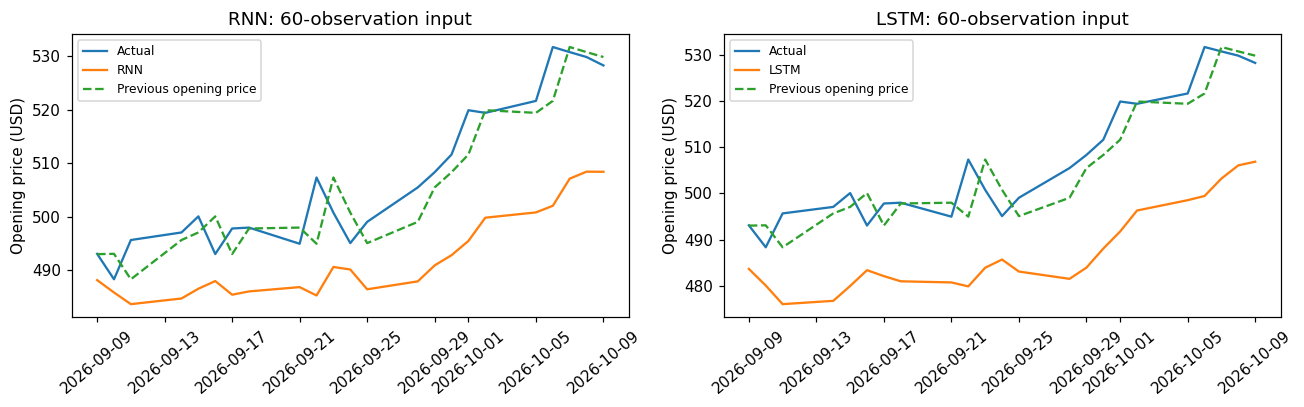

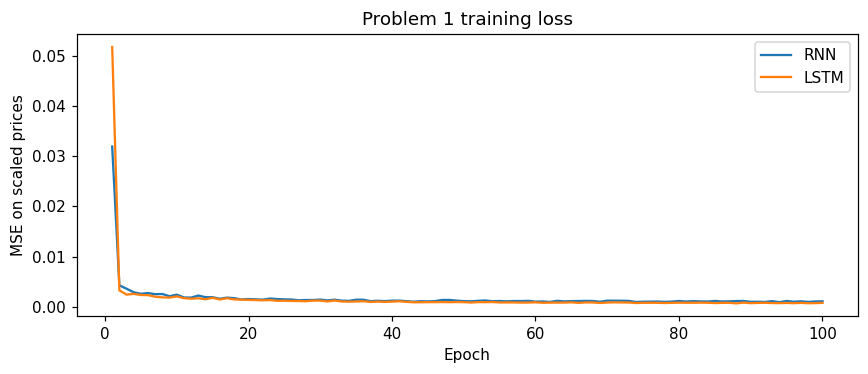

The **RNN** has test RMSE **\$16.59**, higher than persistence at **\$5.32**.<br>
Following the price trend alone does not establish a forecasting improvement.

The **LSTM** has test RMSE **\$20.84**, higher than persistence at **\$5.32**.<br>
Following the price trend alone does not establish a forecasting improvement.

In [5]:
def stock_problem1_experiment():
    # Problem 1 follows the original full-development training formulation.
    p1_stock_scaler = MinMaxScaler().fit(stock_raw[:stock_development_count])
    p1_train_origins = np.arange(60, stock_development_count)
    p1_test_origins = stock_test_origins(1)
    p1_stock_results, p1_stock_histories, p1_stock_predictions = [], {}, {}
    for stock_kind in ("RNN", "LSTM"):
        run_name = f"p1_{stock_kind.lower()}_60"
        fitted_model, run_record, history = stock_fit_model(
            run_name, stock_kind, 60, 1, p1_stock_scaler, p1_train_origins)
        test_metrics, predictions = stock_evaluate(
            fitted_model, p1_stock_scaler, p1_test_origins, 60, 1, run_name, "test")
        p1_stock_results.append({"model": stock_kind, **test_metrics})
        p1_stock_histories[stock_kind] = history
        p1_stock_predictions[stock_kind] = predictions
        del fitted_model
        gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()
    p1_stock_table = pd.DataFrame(p1_stock_results)
    p1_stock_table.to_csv(STOCK_DIR / "problem1_metrics.csv", index=False)
    display(p1_stock_table.round(3))

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    for ax, kind in zip(axes, ("RNN", "LSTM")):
        rows = p1_stock_predictions[kind]
        dates = pd.to_datetime(rows["target_date"])
        ax.plot(dates, rows["actual_open"], label="Actual")
        ax.plot(dates, rows["predicted_open"], label=kind)
        ax.plot(dates, rows["persistence_open"], "--", label="Previous opening price")
        ax.set(title=f"{kind}: 60-observation input", ylabel="Opening price (USD)")
        ax.tick_params(axis="x", rotation=40)
        ax.legend(fontsize=8)
    fig.tight_layout()
    save_figure(fig, "problem1_stock_predictions.png")
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for kind, history in p1_stock_histories.items():
        ax.plot([row["epoch"] for row in history], [row["train_mse_scaled"] for row in history], label=kind)
    ax.set(title="Problem 1 training loss", xlabel="Epoch", ylabel="MSE on scaled prices")
    ax.legend()
    fig.tight_layout()
    save_figure(fig, "problem1_stock_training.png")
    for row in p1_stock_results:
        verdict = "lower" if row["rmse_usd"] < row["baseline_rmse_usd"] else "higher"
        display(Markdown(f"The **{row['model']}** has test RMSE **\\${row['rmse_usd']:.2f}**, "
                         f"{verdict} than persistence at **\\${row['baseline_rmse_usd']:.2f}**.<br>\n"
                         "Following the price trend alone does not establish a forecasting improvement."))
    return p1_stock_results, p1_stock_histories, p1_stock_predictions, p1_stock_table

p1_stock_results, p1_stock_histories, p1_stock_predictions, p1_stock_table = stock_problem1_experiment()

## Problem 2. Use chronological validation and change the forecast

I divide the original development rows chronologically: the first 80% are training data and the final 20% are validation data.<br>
A new scaler is fitted only to that earlier training portion.<br>
All Problem 2 models start with fresh weights; none uses the Problem 1 weights fitted to the whole development period.<br>
Validation chooses the checkpoint and the one-step lookback separately for each model type.<br>
The test period is reserved for the final comparison.

For the one-step experiment, I use lookbacks of 10, 30, 60 and 120 trading observations.<br>
All eight runs use the same training target dates after a common 120-observation warm-up, <br>and the same validation and test target dates.<br>
This keeps differences in the number of training examples out of the lookback comparison.<br>
A validation input may contain earlier training observations, because those observations were already known before its target date.

In [6]:
# Set boundaries before building examples, so targets cannot cross a split.
stock_training_rows = int(np.floor(0.80 * stock_development_count))
assert stock_training_rows > 120
p2_stock_scaler = MinMaxScaler().fit(stock_raw[:stock_training_rows])
p2_train_origins = np.arange(120, stock_training_rows)
p2_validation_origins = np.arange(stock_training_rows, stock_development_count)
p2_test_origins = stock_test_origins(1)
assert p2_train_origins.max() < stock_training_rows
assert p2_validation_origins.min() == stock_training_rows
assert p2_validation_origins.max() < stock_development_count
assert set(p2_train_origins).isdisjoint(p2_validation_origins)
assert p2_stock_scaler.n_samples_seen_ == stock_training_rows
np.testing.assert_allclose(p2_stock_scaler.data_min_, stock_raw[:stock_training_rows].min(axis=0))
np.testing.assert_allclose(p2_stock_scaler.data_max_, stock_raw[:stock_training_rows].max(axis=0))
stock_split_manifest = {
    "company": "Microsoft", "ticker": "MSFT", "development_rows": stock_development_count,
    "training_rows": stock_training_rows, "validation_rows": stock_development_count - stock_training_rows,
    "split_fraction_requested": 0.80, "common_one_step_warmup": 120,
    "training_dates": stock_dates[:stock_training_rows].strftime("%Y-%m-%d").tolist(),
    "validation_dates": stock_dates[stock_training_rows:stock_development_count].strftime("%Y-%m-%d").tolist(),
    "test_dates": stock_dates[stock_test_positions].strftime("%Y-%m-%d").tolist(),
    "context_only_dates": stock_dates[stock_context_only_positions].strftime("%Y-%m-%d").tolist(),
    "p2_scaler": stock_scaler_record(p2_stock_scaler),
    "one_step_train_origins": p2_train_origins.tolist(),
    "one_step_validation_origins": p2_validation_origins.tolist(),
    "one_step_test_origins": p2_test_origins.tolist(),
}
(STOCK_DIR / "split_manifest.json").write_text(json.dumps(stock_split_manifest, indent=2), encoding="utf-8")
print(f"Chronological split: {stock_training_rows} training rows; "
      f"{stock_development_count - stock_training_rows} validation rows.")
print("Training ends:", stock_dates[stock_training_rows - 1].date(),
      "; validation starts:", stock_dates[stock_training_rows].date())
print("Scaler fitted to:", p2_stock_scaler.n_samples_seen_, "training prices only.")
print("One-step example counts:", len(p2_train_origins), "training;",
      len(p2_validation_origins), "validation;", len(p2_test_origins), "test.")

Chronological split: 2147 training rows; 537 validation rows.
Training ends: 2024-07-16 ; validation starts: 2024-07-17
Scaler fitted to: 2147 training prices only.
One-step example counts: 2027 training; 537 validation; 23 test.


In [7]:
def stock_train_lookback_experiments():
    # Train all lookbacks and select them using validation results only.
    p2_lookback_results = []
    p2_lookback_histories = {}
    for stock_kind in ("RNN", "LSTM"):
        for stock_lookback in (10, 30, 60, 120):
            run_name = f"p2_{stock_kind.lower()}_{stock_lookback}"
            fitted_model, run_record, history = stock_fit_model(
                run_name, stock_kind, stock_lookback, 1, p2_stock_scaler,
                p2_train_origins, p2_validation_origins)
            val_metrics, _ = stock_evaluate(
                fitted_model, p2_stock_scaler, p2_validation_origins,
                stock_lookback, 1, run_name, "validation")
            p2_lookback_results.append({"run_name": run_name, "model": stock_kind,
                                        "lookback": stock_lookback,
                                        "selected_epoch": run_record["selected_epoch"],
                                        **{"validation_" + key: value for key, value in val_metrics.items()}})
            p2_lookback_histories[run_name] = history
            del fitted_model
            gc.collect()
            if device.type == "cuda":
                torch.cuda.empty_cache()
    p2_validation_table = pd.DataFrame(p2_lookback_results)
    selected_stock_lookbacks = {
        kind: int(p2_validation_table.loc[p2_validation_table["model"].eq(kind)]
                  .sort_values(["validation_rmse_usd", "lookback"]).iloc[0]["lookback"])
        for kind in ("RNN", "LSTM")}
    (STOCK_DIR / "lookback_selection.json").write_text(json.dumps({
        "selection_metric": "validation RMSE in USD", "test_results_used": False,
        "selected_lookbacks": selected_stock_lookbacks,
        "candidates": p2_lookback_results}, indent=2), encoding="utf-8")
    print("Lookbacks selected before test evaluation:", selected_stock_lookbacks)
    display(p2_validation_table[["model", "lookback", "selected_epoch", "validation_mae_usd",
                                  "validation_rmse_usd"]].round(3))
    return p2_lookback_results, p2_lookback_histories, selected_stock_lookbacks, p2_validation_table

p2_lookback_results, p2_lookback_histories, selected_stock_lookbacks, p2_validation_table = stock_train_lookback_experiments()

p2_rnn_10: inputs (2027, 10, 1); targets (2027, 1); parameters 18,001


  epoch 001: training MSE 0.033558; validation MSE 0.017825; 0.35 s
  first-epoch estimate: 0.6 minutes


  epoch 050: training MSE 0.000983; validation MSE 0.003544; 0.31 s


  epoch 100: training MSE 0.000761; validation MSE 0.002114; 0.31 s
  selected epoch 88; reload verified; total 0.5 minutes


p2_rnn_30: inputs (2027, 30, 1); targets (2027, 1); parameters 18,001


...

  epoch 001: training MSE 0.054370; validation MSE 0.027162; 0.47 s
  first-epoch estimate: 0.8 minutes


  epoch 050: training MSE 0.000817; validation MSE 0.002561; 0.35 s


  epoch 100: training MSE 0.000691; validation MSE 0.003005; 0.36 s
  selected epoch 55; reload verified; total 0.6 minutes


Lookbacks selected before test evaluation: {'RNN': 60, 'LSTM': 120}


,model,lookback,selected_epoch,validation_mae_usd,validation_rmse_usd
0,RNN,10,88,11.886,14.705
1,RNN,30,74,11.589,14.273
2,RNN,60,68,10.842,13.723
3,RNN,120,40,11.407,14.407
4,LSTM,10,68,14.743,18.874
5,LSTM,30,61,12.797,16.669
6,LSTM,60,40,13.073,17.353
7,LSTM,120,55,12.831,16.480


,model,lookback,selected_epoch,validation_rmse_usd,test_mae_usd,test_rmse_usd,test_baseline_rmse_usd,selected_by_validation
0,RNN,10,88,14.705,20.047,21.533,5.325,False
1,RNN,30,74,14.273,16.308,18.319,5.325,False
2,RNN,60,68,13.723,18.123,19.779,5.325,True
3,RNN,120,40,14.407,17.574,19.432,5.325,False
4,LSTM,10,68,18.874,23.858,26.629,5.325,False
5,LSTM,30,61,16.669,19.746,22.476,5.325,False
6,LSTM,60,40,17.353,10.075,13.402,5.325,False
7,LSTM,120,55,16.480,16.462,19.439,5.325,True


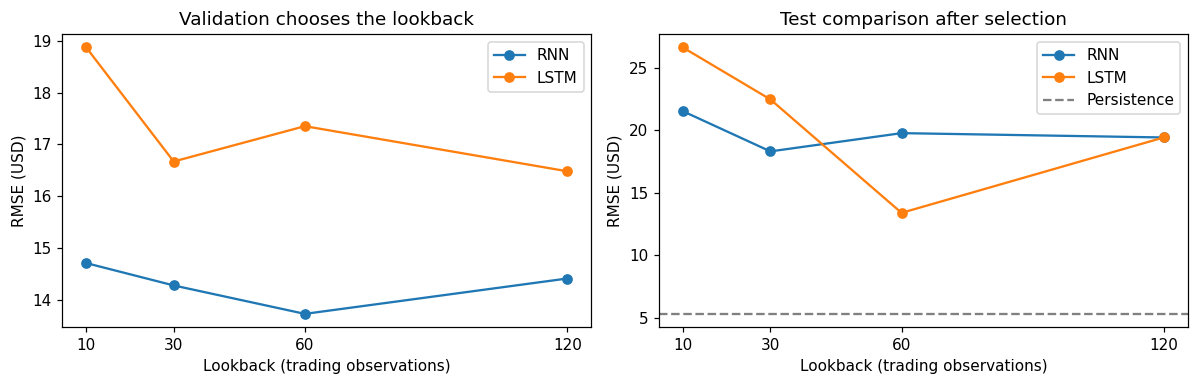

For **RNN**, validation selects **60 observations**, with validation RMSE **\$13.72**.<br>
Its test RMSE is **\$19.78**; it does not beat persistence (**\$5.32**) on this test period.

For **LSTM**, validation selects **120 observations**, with validation RMSE **\$16.48**.<br>
Its test RMSE is **\$19.44**; it does not beat persistence (**\$5.32**) on this test period.

In [8]:
def stock_test_lookback_experiments():
    # With selection fixed, restore each checkpoint and evaluate the test period.
    p2_all_lookback_results, p2_selected_predictions = [], {}
    for row in p2_lookback_results:
        saved = torch.load(STOCK_DIR / f"{row['run_name']}.pt", map_location="cpu", weights_only=True)
        test_model = StockSequenceModel(**saved["model_config"]).to(device)
        test_model.load_state_dict(saved["model_state_dict"])
        test_scaler = stock_restore_scaler(saved["scaler"])
        metrics, predictions = stock_evaluate(test_model, test_scaler, p2_test_origins,
                                              row["lookback"], 1, row["run_name"], "test")
        p2_all_lookback_results.append({**row, **{"test_" + key: value for key, value in metrics.items()},
                                       "selected_by_validation": row["lookback"] == selected_stock_lookbacks[row["model"]]})
        if row["lookback"] == selected_stock_lookbacks[row["model"]]:
            p2_selected_predictions[row["model"]] = predictions
        del test_model
    p2_stock_table = pd.DataFrame(p2_all_lookback_results)
    p2_stock_table.to_csv(STOCK_DIR / "problem2_lookback_metrics.csv", index=False)
    display(p2_stock_table[["model", "lookback", "selected_epoch", "validation_rmse_usd",
                             "test_mae_usd", "test_rmse_usd", "test_baseline_rmse_usd",
                             "selected_by_validation"]].round(3))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for kind in ("RNN", "LSTM"):
        rows = p2_stock_table.loc[p2_stock_table["model"].eq(kind)].sort_values("lookback")
        axes[0].plot(rows["lookback"], rows["validation_rmse_usd"], marker="o", label=kind)
        axes[1].plot(rows["lookback"], rows["test_rmse_usd"], marker="o", label=kind)
    axes[0].set(title="Validation chooses the lookback", xlabel="Lookback (trading observations)", ylabel="RMSE (USD)")
    axes[1].axhline(p2_stock_table.iloc[0]["test_baseline_rmse_usd"], color="gray", linestyle="--", label="Persistence")
    axes[1].set(title="Test comparison after selection", xlabel="Lookback (trading observations)", ylabel="RMSE (USD)")
    for ax in axes:
        ax.set_xticks([10, 30, 60, 120])
        ax.legend()
    fig.tight_layout()
    save_figure(fig, "problem2_lookback_comparison.png")
    for kind, lookback in selected_stock_lookbacks.items():
        row = p2_stock_table.loc[p2_stock_table["model"].eq(kind) & p2_stock_table["lookback"].eq(lookback)].iloc[0]
        verdict = "beats" if row["test_rmse_usd"] < row["test_baseline_rmse_usd"] else "does not beat"
        display(Markdown(f"For **{kind}**, validation selects **{lookback} observations**, "
                         f"with validation RMSE **\\${row['validation_rmse_usd']:.2f}**.<br>\n"
                         f"Its test RMSE is **\\${row['test_rmse_usd']:.2f}**; it {verdict} "
                         f"persistence (**\\${row['test_baseline_rmse_usd']:.2f}**) on this test period."))
    return p2_stock_table, p2_selected_predictions

p2_stock_table, p2_selected_predictions = stock_test_lookback_experiments()

### Predict five future opening prices from a `(60, 1)` input

The next experiment fixes the input at 60 past trading observations and changes the target to a vector of five future opening prices.<br>
The output layer now has five units, so one forward pass predicts all five prices directly.<br>
A later predicted price is not fed back as an input.

All five targets must lie within the same training, validation or test period.<br><br>
I drop examples whose targets would cross a boundary.<br>
Past inputs can still include observations from an earlier period.<br>
Five steps means five trading observations, which can span more than five calendar days.<br>
The persistence baseline repeats the last observed opening price at every horizon.<br>
I show errors separately for horizons one through five and an aggregate across all origin–horizon pairs.<br>
Adjacent forecasts overlap, so these aggregate errors do not describe independent observations.

Five-step training input shape: (2083, 60, 1)
Five-step training target shape: (2083, 5)
First training target: [[54.95 55.05 55.43 55.19 54.36]]
p2_rnn_60_five: inputs (2083, 60, 1); targets (2083, 5); parameters 18,205


  epoch 001: training MSE 0.043460; validation MSE 0.019935; 0.37 s
  first-epoch estimate: 0.6 minutes


  epoch 050: training MSE 0.001349; validation MSE 0.002041; 0.34 s


  epoch 100: training MSE 0.000977; validation MSE 0.002039; 0.33 s
  selected epoch 90; reload verified; total 0.6 minutes


p2_lstm_60_five: inputs (2083, 60, 1); targets (2083, 5); parameters 72,055


  epoch 001: training MSE 0.077223; validation MSE 0.132324; 0.38 s
  first-epoch estimate: 0.6 minutes


  epoch 050: training MSE 0.001046; validation MSE 0.002512; 0.38 s


  epoch 100: training MSE 0.000797; validation MSE 0.002625; 0.37 s
  selected epoch 73; reload verified; total 0.6 minutes


,model,selected_epoch,validation_rmse_usd,test_mae_usd,test_rmse_usd,test_baseline_rmse_usd,test_origins,test_target_cells
0,RNN,90,16.469,17.601,19.664,9.166,19,95
1,LSTM,73,18.367,15.794,18.838,9.166,19,95


,model,horizon,forecast_origins,mae_usd,rmse_usd,baseline_mae_usd,baseline_rmse_usd
0,RNN,1,19,14.312,15.722,4.405,5.364
1,RNN,2,19,16.683,18.532,6.464,7.373
2,RNN,3,19,17.770,19.706,7.137,8.575
3,RNN,4,19,19.202,21.340,8.606,10.577
4,RNN,5,19,20.040,22.338,9.723,12.310
5,LSTM,1,19,12.246,14.444,4.405,5.364
6,LSTM,2,19,14.663,17.297,6.464,7.373
7,LSTM,3,19,16.930,19.807,7.137,8.575
8,LSTM,4,19,18.084,21.214,8.606,10.577
9,LSTM,5,19,17.050,20.598,9.723,12.310


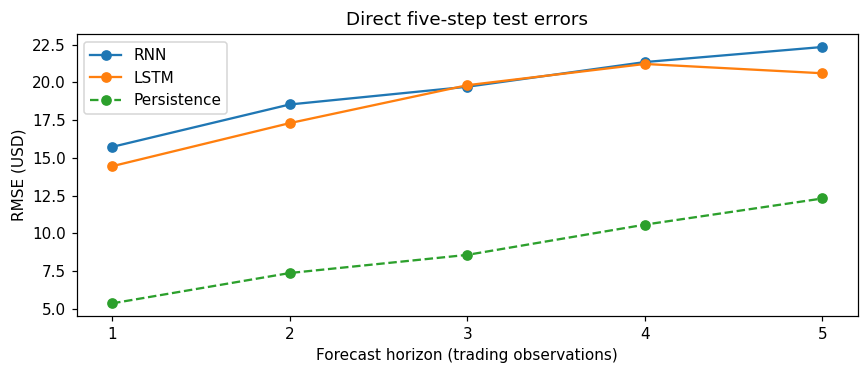

The direct five-step **RNN** has aggregate test RMSE **\$19.66**, higher than persistence at **\$9.17**.<br>
This uses **19 forecast origins**, each with five targets.<br>
The horizon table shows whether errors differ as the forecast moves further ahead.

The direct five-step **LSTM** has aggregate test RMSE **\$18.84**, higher than persistence at **\$9.17**.<br>
This uses **19 forecast origins**, each with five targets.<br>
The horizon table shows whether errors differ as the forecast moves further ahead.

In [9]:
def stock_five_step_experiment():
    # Construct direct five-step targets without crossing a target split boundary.
    p2_five_train_origins = np.arange(60, stock_training_rows - 5 + 1)
    p2_five_validation_origins = np.arange(stock_training_rows, stock_development_count - 5 + 1)
    p2_five_test_origins = stock_test_origins(5)
    assert p2_five_train_origins.max() + 4 < stock_training_rows
    assert p2_five_validation_origins.min() >= stock_training_rows
    assert p2_five_validation_origins.max() + 4 < stock_development_count
    assert all(all(i + h in stock_test_position_set for h in range(5))
               for i in p2_five_test_origins)
    five_scaled = p2_stock_scaler.transform(stock_raw).astype(np.float32)
    five_x, five_y = stock_windows(five_scaled, p2_five_train_origins, 60, 5)
    print("Five-step training input shape:", five_x.shape)
    print("Five-step training target shape:", five_y.shape)
    print("First training target:", stock_unscale(five_y[:1], p2_stock_scaler).round(2))
    (STOCK_DIR / "five_step_window_manifest.json").write_text(json.dumps({
        "lookback": 60, "horizon": 5, "train_origins": p2_five_train_origins.tolist(),
        "validation_origins": p2_five_validation_origins.tolist(),
        "test_origins": p2_five_test_origins.tolist(),
        "train_input_shape": list(five_x.shape), "train_target_shape": list(five_y.shape),
        "target_boundaries_checked": True}, indent=2), encoding="utf-8")
    p2_five_results, p2_five_horizon_rows, p2_five_predictions = [], [], {}
    for kind in ("RNN", "LSTM"):
        run_name = f"p2_{kind.lower()}_60_five"
        model, run_record, history = stock_fit_model(
            run_name, kind, 60, 5, p2_stock_scaler,
            p2_five_train_origins, p2_five_validation_origins)
        validation_metrics, _ = stock_evaluate(model, p2_stock_scaler, p2_five_validation_origins,
                                               60, 5, run_name, "validation")
        test_metrics, predictions = stock_evaluate(model, p2_stock_scaler, p2_five_test_origins,
                                                   60, 5, run_name, "test")
        p2_five_predictions[kind] = predictions
        p2_five_results.append({"model": kind, "lookback": 60, "horizon": 5,
                                "selected_epoch": run_record["selected_epoch"],
                                **{"validation_" + key: value for key, value in validation_metrics.items()},
                                **{"test_" + key: value for key, value in test_metrics.items()}})
        for horizon, group in predictions.groupby("horizon", sort=True):
            metric = stock_error_metrics(group["actual_open"], group["predicted_open"])
            baseline_metric = stock_error_metrics(group["actual_open"], group["persistence_open"])
            p2_five_horizon_rows.append({"model": kind, "horizon": int(horizon), "forecast_origins": len(group),
                                         **metric, **{"baseline_" + key: value for key, value in baseline_metric.items()}})
        del model
        gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()
    p2_five_table = pd.DataFrame(p2_five_results)
    p2_horizon_table = pd.DataFrame(p2_five_horizon_rows)
    p2_five_table.to_csv(STOCK_DIR / "problem2_five_step_metrics.csv", index=False)
    p2_horizon_table.to_csv(STOCK_DIR / "problem2_horizon_metrics.csv", index=False)
    display(p2_five_table[["model", "selected_epoch", "validation_rmse_usd", "test_mae_usd",
                            "test_rmse_usd", "test_baseline_rmse_usd", "test_origins", "test_target_cells"]].round(3))
    display(p2_horizon_table.round(3))

    fig, ax = plt.subplots(figsize=(8, 3.5))
    for kind in ("RNN", "LSTM"):
        rows = p2_horizon_table.loc[p2_horizon_table["model"].eq(kind)]
        ax.plot(rows["horizon"], rows["rmse_usd"], marker="o", label=kind)
    baseline_rows = p2_horizon_table.loc[p2_horizon_table["model"].eq("RNN")]
    ax.plot(baseline_rows["horizon"], baseline_rows["baseline_rmse_usd"], "--", marker="o", label="Persistence")
    ax.set(title="Direct five-step test errors", xlabel="Forecast horizon (trading observations)", ylabel="RMSE (USD)", xticks=[1, 2, 3, 4, 5])
    ax.legend()
    fig.tight_layout()
    save_figure(fig, "problem2_five_step_horizons.png")
    for row in p2_five_results:
        verdict = "lower" if row["test_rmse_usd"] < row["test_baseline_rmse_usd"] else "higher"
        display(Markdown(f"The direct five-step **{row['model']}** has aggregate test RMSE "
                         f"**\\${row['test_rmse_usd']:.2f}**, {verdict} than persistence at "
                         f"**\\${row['test_baseline_rmse_usd']:.2f}**.<br>\n"
                         f"This uses **{row['test_origins']} forecast origins**, each with five targets.<br>\n"
                         "The horizon table shows whether errors differ as the forecast moves further ahead."))
    return p2_five_table, p2_horizon_table, p2_five_predictions, p2_five_results

p2_five_table, p2_horizon_table, p2_five_predictions, p2_five_results = stock_five_step_experiment()

### What the stock experiments show

None of the tested neural models beats persistence on this test period.<br>
Longer lookback windows do not improve validation error consistently.<br>
Validation selects 60 observations for the RNN and 120 for the LSTM; their test RMSEs are USD 19.78 and USD 19.44, compared with USD 5.32 for persistence.<br>
The 60-observation LSTM has a lower test RMSE of USD 13.40, but its validation result did not select it.<br>
I keep the choice made before examining the test results.

The direct five-step models also fall short of persistence: aggregate test RMSE is USD 19.66 for the RNN and USD 18.84 for the LSTM, compared with USD 9.17 for persistence.<br>
These figures cover 19 forecast origins and 95 origin–horizon pairs.<br>
Errors generally increase at longer horizons, although the LSTM's fifth-step error is slightly lower than its fourth-step error.<br>
The overlapping forecasts do not provide 95 independent test observations.

The Problem 2 test prices exceed the maximum price used to fit the scaler, so their scaled values exceed one.<br>
I retain that training scale and do not clip the later prices.<br>
These experiments show no forecasting improvement over the most recent observed opening price for the 23 test trading days.

## Problem 3. Increase the translator's vocabulary

I compare vocabulary budgets of **1,000** and **3,000** tokens in the supplied `3_NMT.ipynb` model.<br>
Each language has its own vocabulary, and each budget includes the four reserved tokens.<br>
All other settings remain unchanged.<br>
Both runs use the full filtered corpus, seed 42, a 50-token limit and batches of 64.<br>
Embeddings have 128 values, and the encoder and decoder each have one 512-unit LSTM.<br>
Adam uses a learning rate of 0.001, the gradient norm is clipped at 1.0, and each model trains for 10 epochs.<br>
`QUICK_RUN` remains false.<br>
Each model is restored to its lowest validation-loss epoch.

The data, tokenisation and grouped split follow the starter notebook.<br>
Normalised English sentences cannot cross the training, validation and test boundaries.<br>
The vocabulary is fitted on training text only.<br>
I select the same five held-out English inputs for both models before training, using the starter's short-to-long example selection.

In [10]:
# Reproduce the starter's corpus, tokenisation and grouped random split.
import csv
import hashlib
import math
import random
import re
import time
import unicodedata
import urllib.request
import zipfile
from collections import Counter
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence
from torch.utils.data import DataLoader, Dataset

NMT_DATA_DIR = DATA_DIR / "nmt"
NMT_OUTPUT_DIR = OUTPUT_DIR / "nmt"
NMT_DATA_DIR.mkdir(parents=True, exist_ok=True)
NMT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
NMT_SETTINGS = {
    "QUICK_RUN": False, "MAX_PAIRS": None, "MAX_WORDS": 50,
    "BATCH_SIZE": 64, "EMBED_DIM": 128, "HIDDEN_DIM": 512,
    "EPOCHS": 10, "LEARNING_RATE": 0.001, "CLIP_NORM": 1.0,
    "SEED": 42, "vocabulary_budgets": [1000, 3000],
    "checkpoint_selection": "minimum validation token cross-entropy",
}
assert SEED == NMT_SETTINGS["SEED"]
NMT_URL = "https://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip"
NMT_ARCHIVE_SHA256 = "0c4fd7825d3d872488d38c157f784e035edab4f2ff0df25a2a208790ecb5b58f"
nmt_archive_path = NMT_DATA_DIR / "spa-eng.zip"
if not nmt_archive_path.exists():
    nmt_temporary_path = nmt_archive_path.with_suffix(".download")
    urllib.request.urlretrieve(NMT_URL, nmt_temporary_path)
    nmt_temporary_path.replace(nmt_archive_path)
assert hashlib.sha256(nmt_archive_path.read_bytes()).hexdigest() == NMT_ARCHIVE_SHA256
with zipfile.ZipFile(nmt_archive_path) as nmt_archive:
    nmt_text_members = [name for name in nmt_archive.namelist()
                        if Path(name).name == "spa.txt"]
    assert len(nmt_text_members) == 1
    nmt_raw_text = nmt_archive.read(nmt_text_members[0]).decode("utf-8-sig")
    nmt_about = [name for name in nmt_archive.namelist()
                 if Path(name).name == "_about.txt"]
    if nmt_about:
        (NMT_OUTPUT_DIR / "corpus_attribution.txt").write_bytes(nmt_archive.read(nmt_about[0]))

def nmt_tokenize(text):
    text = unicodedata.normalize("NFC", text).lower()
    return re.findall(r"\w+(?:['’]\w+)*|[^\w\s]", text, flags=re.UNICODE)

def nmt_detokenize(tokens):
    text = " ".join(tokens)
    text = re.sub(r"\s+([.,!?;:])", r"\1", text)
    return re.sub(r"([¿¡])\s+", r"\1", text)

nmt_raw_pairs = []
for nmt_line in nmt_raw_text.splitlines():
    nmt_fields = nmt_line.split("\t")
    if len(nmt_fields) >= 2 and nmt_fields[0].strip() and nmt_fields[1].strip():
        nmt_raw_pairs.append((nmt_fields[0].strip(), nmt_fields[1].strip()))
nmt_pairs, nmt_seen = [], set()
for nmt_source, nmt_target in nmt_raw_pairs:
    nmt_source_tokens, nmt_target_tokens = nmt_tokenize(nmt_source), nmt_tokenize(nmt_target)
    nmt_key = (tuple(nmt_source_tokens), tuple(nmt_target_tokens))
    if (0 < len(nmt_source_tokens) <= NMT_SETTINGS["MAX_WORDS"]
            and 0 < len(nmt_target_tokens) <= NMT_SETTINGS["MAX_WORDS"]
            and nmt_key not in nmt_seen):
        nmt_pairs.append((nmt_source_tokens, nmt_target_tokens))
        nmt_seen.add(nmt_key)

# Keep both shuffles and their order identical to the starter.
nmt_rng = random.Random(SEED)
nmt_rng.shuffle(nmt_pairs)
nmt_groups = {}
for nmt_source, nmt_target in nmt_pairs:
    nmt_groups.setdefault(tuple(nmt_source), []).append((nmt_source, nmt_target))
nmt_source_keys = list(nmt_groups)
nmt_rng.shuffle(nmt_source_keys)
nmt_train_end = int(0.8 * len(nmt_source_keys))
nmt_valid_end = int(0.9 * len(nmt_source_keys))

def nmt_collect_pairs(keys):
    return [pair for key in keys for pair in nmt_groups[key]]

nmt_train_pairs = nmt_collect_pairs(nmt_source_keys[:nmt_train_end])
nmt_valid_pairs = nmt_collect_pairs(nmt_source_keys[nmt_train_end:nmt_valid_end])
nmt_test_pairs = nmt_collect_pairs(nmt_source_keys[nmt_valid_end:])
nmt_split_keys = [set(tuple(pair[0]) for pair in split)
                  for split in (nmt_train_pairs, nmt_valid_pairs, nmt_test_pairs)]
assert all(nmt_split_keys[a].isdisjoint(nmt_split_keys[b])
           for a, b in ((0, 1), (0, 2), (1, 2)))
assert sum(map(len, (nmt_train_pairs, nmt_valid_pairs, nmt_test_pairs))) == len(nmt_pairs)
with (NMT_OUTPUT_DIR / "split_manifest.csv").open("w", encoding="utf-8", newline="") as nmt_stream:
    nmt_writer = csv.writer(nmt_stream)
    nmt_writer.writerow(["split", "english_tokens", "spanish_tokens"])
    for nmt_split_name, nmt_rows in (("train", nmt_train_pairs), ("validation", nmt_valid_pairs),
                                     ("test", nmt_test_pairs)):
        nmt_writer.writerows((nmt_split_name, " ".join(source), " ".join(target))
                             for source, target in nmt_rows)
nmt_manifest = {
    "source_url": NMT_URL, "archive_sha256": NMT_ARCHIVE_SHA256,
    "archive_date": "2018-05-13", "raw_pairs": len(nmt_raw_pairs),
    "retained_pairs": len(nmt_pairs), "source_groups": len(nmt_groups),
    "split_pair_counts": {"train": len(nmt_train_pairs), "validation": len(nmt_valid_pairs),
                          "test": len(nmt_test_pairs)},
    "split_group_counts": {name: len(keys) for name, keys in
                           zip(("train", "validation", "test"), nmt_split_keys)},
    "source_notebook_sha256": "d7ea900529283d49a280e09da2438a4f6e531053e93d4efe3115b123f628224f",
}
(NMT_OUTPUT_DIR / "settings.json").write_text(json.dumps(NMT_SETTINGS, indent=2), encoding="utf-8")
(NMT_OUTPUT_DIR / "data_provenance.json").write_text(json.dumps(nmt_manifest, indent=2), encoding="utf-8")

# The source notebook samples five positions after sorting by English length.
nmt_ordered_test_indices = sorted(range(len(nmt_test_pairs)),
                                  key=lambda index: len(nmt_test_pairs[index][0]))
nmt_positions = np.linspace(0, len(nmt_ordered_test_indices) - 1, num=5, dtype=int)
nmt_five_indices = [nmt_ordered_test_indices[int(position)] for position in nmt_positions]
nmt_five_examples = [
    {"test_index": index, "english": nmt_detokenize(nmt_test_pairs[index][0]),
     "reference": nmt_detokenize(nmt_test_pairs[index][1]),
     "source_tokens": nmt_test_pairs[index][0], "target_tokens": nmt_test_pairs[index][1]}
    for index in nmt_five_indices]
assert len({tuple(row["source_tokens"]) for row in nmt_five_examples}) == 5
(NMT_OUTPUT_DIR / "five_sources.json").write_text(
    json.dumps(nmt_five_examples, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Read {len(nmt_raw_pairs):,} pairs; retained {len(nmt_pairs):,} distinct normalised pairs.")
print("Pair counts:", nmt_manifest["split_pair_counts"])
print("No normalised English source appears in more than one split.")
display(pd.DataFrame(nmt_five_examples)[["test_index", "english", "reference"]])

Read 118,964 pairs; retained 118,960 distinct normalised pairs.
Pair counts: {'train': 95096, 'validation': 11955, 'test': 11909}
No normalised English source appears in more than one split.


,test_index,english,reference
0,2937,hi.,hola.
1,197,i am a good boy.,soy un buen tipo.
2,6351,may i turn on the radio?,¿te importa que encienda la radio?
3,3146,tom is looking forward to seeing mary again.,tom está deseando volver a ver a mary.
4,10760,"even now, i occasionally think i'd like to see you. not the you that you are today, but the you i remember from the past.","incluso ahora, a veces pienso que me gustaría verte. no como eres hoy, sino como te recuerdo."


### Vocabulary, model and measurements

Both vocabularies use the starter's frequency ranking and alphabetical tie-breaking.<br>
The encoder reads the packed English sequence and passes its hidden and cell states to the Spanish decoder.<br>
Training uses the correct preceding Spanish token; inference feeds back the model's own prediction.<br>
The decoder uses the same greedy search and 51-step limit as the starter.

The unknown-token percentage is the number of `<unk>` occurrences divided by the number of original content tokens.<br>
It includes punctuation, as in the supplied notebook, and excludes padding and boundary markers.<br>
I also save word-only unknown counts, with punctuation excluded, to make this distinction explicit.

The requested validation accuracy follows the starter: padding is excluded, while `<eos>` and matching `<unk>` labels count.<br>
This can reward a small vocabulary for predicting an unknown marker.<br>
I therefore also report accuracy with every `<unk>` target counted as an error, keeping the same denominator of non-padding target positions.<br>
Neither teacher-forced accuracy is a percentage of sentences translated correctly.<br>
Losses and perplexities from different vocabulary sizes should not be read as directly comparable translation-quality scores.

In [11]:
# Keep the encoder-decoder architecture and all training settings unchanged.
NMT_PAD, NMT_UNK, NMT_BOS, NMT_EOS = 0, 1, 2, 3
NMT_SPECIAL_TOKENS = ["<pad>", "<unk>", "<bos>", "<eos>"]

class NmtVocabulary:
    def __init__(self, token_sequences, max_size):
        counts = Counter(token for sequence in token_sequences for token in sequence)
        ranked = sorted(counts, key=lambda token: (-counts[token], token))
        self.itos = NMT_SPECIAL_TOKENS + [token for token in ranked if token not in NMT_SPECIAL_TOKENS][
            :max_size - len(NMT_SPECIAL_TOKENS)]
        self.stoi = {token: index for index, token in enumerate(self.itos)}

    def __len__(self):
        return len(self.itos)

    def encode(self, tokens):
        return [self.stoi.get(token, NMT_UNK) for token in tokens]

    def decode(self, ids):
        return [self.itos[index] for index in ids]

def nmt_unknown_counts(pairs, side, vocabulary):
    tokens = [token for pair in pairs for token in pair[side]]
    unknown = sum(token not in vocabulary.stoi for token in tokens)
    words = [token for token in tokens if re.fullmatch(r"\w+(?:['’]\w+)*", token)]
    unknown_words = sum(token not in vocabulary.stoi for token in words)
    return {"unknown_tokens": unknown, "content_tokens": len(tokens),
            "unknown_rate": unknown / len(tokens), "unknown_words": unknown_words,
            "words": len(words), "word_unknown_rate": unknown_words / len(words)}

class NmtTranslationDataset(Dataset):
    def __init__(self, pairs, source_vocab, target_vocab):
        self.examples = []
        for source, target in pairs:
            source_ids = torch.tensor(source_vocab.encode(source), dtype=torch.long)
            target_ids = torch.tensor([NMT_BOS] + target_vocab.encode(target) + [NMT_EOS], dtype=torch.long)
            self.examples.append((source_ids, target_ids[:-1], target_ids[1:]))

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        return self.examples[index]

def nmt_collate_batch(examples):
    sources, decoder_inputs, labels = zip(*examples)
    lengths = torch.tensor([len(source) for source in sources], dtype=torch.long)
    return (pad_sequence(sources, batch_first=True, padding_value=NMT_PAD), lengths,
            pad_sequence(decoder_inputs, batch_first=True, padding_value=NMT_PAD),
            pad_sequence(labels, batch_first=True, padding_value=NMT_PAD))

class NmtEncoder(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=NMT_PAD)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)

    def forward(self, source_ids, source_lengths):
        embedded = self.embedding(source_ids)
        packed = pack_padded_sequence(embedded, source_lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, state = self.lstm(packed)
        return state

class NmtDecoder(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=NMT_PAD)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.output = nn.Linear(hidden_dim, vocab_size)

    def forward(self, decoder_ids, state):
        embedded = self.embedding(decoder_ids)
        hidden_sequence, state = self.lstm(embedded, state)
        return self.output(hidden_sequence), state

class NmtSeq2Seq(nn.Module):
    def __init__(self, source_size, target_size, embed_dim, hidden_dim):
        super().__init__()
        self.encoder = NmtEncoder(source_size, embed_dim, hidden_dim)
        self.decoder = NmtDecoder(target_size, embed_dim, hidden_dim)

    def forward(self, source_ids, source_lengths, decoder_ids):
        state = self.encoder(source_ids, source_lengths)
        logits, _ = self.decoder(decoder_ids, state)
        return logits

def nmt_run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_correct, resolved_correct, total_tokens, unknown_targets = 0.0, 0, 0, 0, 0
    with torch.set_grad_enabled(training):
        for source_ids, source_lengths, decoder_ids, labels in loader:
            source_ids, decoder_ids, labels = source_ids.to(device), decoder_ids.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(source_ids, source_lengths, decoder_ids)
            loss_sum = F.cross_entropy(logits.reshape(-1, logits.size(-1)), labels.reshape(-1),
                                       ignore_index=NMT_PAD, reduction="sum")
            mask = labels.ne(NMT_PAD)
            token_count = int(mask.sum().item())
            if training:
                (loss_sum / token_count).backward()
                nn.utils.clip_grad_norm_(model.parameters(), NMT_SETTINGS["CLIP_NORM"])
                optimizer.step()
            correct = logits.detach().argmax(-1).eq(labels) & mask
            total_loss += float(loss_sum.detach().item())
            total_correct += int(correct.sum().item())
            resolved_correct += int((correct & labels.ne(NMT_UNK)).sum().item())
            unknown_targets += int((labels.eq(NMT_UNK) & mask).sum().item())
            total_tokens += token_count
    return {"loss": total_loss / total_tokens, "accuracy": total_correct / total_tokens,
            "accuracy_unk_as_error": resolved_correct / total_tokens,
            "correct_tokens": total_correct, "resolved_correct_tokens": resolved_correct,
            "tokens": total_tokens, "unknown_targets": unknown_targets}

@torch.inference_mode()
def nmt_translate(sentence, model, source_vocab, target_vocab, max_steps=51):
    tokens = nmt_tokenize(sentence)
    if not tokens or len(tokens) > NMT_SETTINGS["MAX_WORDS"]:
        raise ValueError("Use one to 50 source tokens, including punctuation.")
    if max_steps < 1:
        raise ValueError("max_steps must be positive.")
    model.eval()
    model_device = next(model.parameters()).device
    source_ids = torch.tensor([source_vocab.encode(tokens)], dtype=torch.long, device=model_device)
    lengths = torch.tensor([len(tokens)], dtype=torch.long)
    state = model.encoder(source_ids, lengths)
    next_input = torch.tensor([[NMT_BOS]], dtype=torch.long, device=model_device)
    generated, ended = [], False
    for _ in range(max_steps):
        logits, state = model.decoder(next_input, state)
        scores = logits[0, -1].clone()
        scores[[NMT_PAD, NMT_BOS]] = -torch.inf
        next_id = int(scores.argmax().item())
        if next_id == NMT_EOS:
            ended = True
            break
        generated.append(next_id)
        next_input = torch.tensor([[next_id]], dtype=torch.long, device=model_device)
    return {"translation": nmt_detokenize(target_vocab.decode(generated)),
            "ended_with_eos": ended,
            "unknown_source_tokens": [token for token in tokens if token not in source_vocab.stoi]}

def nmt_restore_vocab(tokens):
    vocabulary = NmtVocabulary([], len(tokens))
    vocabulary.itos = list(tokens)
    vocabulary.stoi = {token: index for index, token in enumerate(tokens)}
    return vocabulary

### Train both vocabulary budgets

Each experiment starts from a new model and the same seed.<br>
The batches use a separate generator with the same seed, so the examples occur in the same order for both vocabulary budgets.<br>
The initial batch inspection is retained from the source notebook.<br>
I save a CPU checkpoint when validation loss improves and save the completed training history.<br>
A fresh model and its saved vocabularies must reproduce all five generated translations after reloading.

In [12]:
# Train the full corpus for all ten epochs at each vocabulary budget.
def nmt_train_experiment(vocabulary_budget):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    source_vocab = NmtVocabulary((source for source, _ in nmt_train_pairs), vocabulary_budget)
    target_vocab = NmtVocabulary((target for _, target in nmt_train_pairs), vocabulary_budget)
    assert len(source_vocab) == len(target_vocab) == vocabulary_budget
    coverage = {split_name: {language: nmt_unknown_counts(rows, side, vocabulary)
                            for language, side, vocabulary in
                            (("english", 0, source_vocab), ("spanish", 1, target_vocab))}
                for split_name, rows in (("train", nmt_train_pairs), ("validation", nmt_valid_pairs),
                                         ("test", nmt_test_pairs))}
    datasets = [NmtTranslationDataset(rows, source_vocab, target_vocab)
                for rows in (nmt_train_pairs, nmt_valid_pairs, nmt_test_pairs)]
    loader_generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(datasets[0], batch_size=NMT_SETTINGS["BATCH_SIZE"], shuffle=True,
                              collate_fn=nmt_collate_batch, num_workers=0, generator=loader_generator)
    valid_loader = DataLoader(datasets[1], batch_size=NMT_SETTINGS["BATCH_SIZE"],
                              collate_fn=nmt_collate_batch, num_workers=0)
    test_loader = DataLoader(datasets[2], batch_size=NMT_SETTINGS["BATCH_SIZE"],
                             collate_fn=nmt_collate_batch, num_workers=0)
    # This consumes the same initial shuffled batch as the starter.
    batch = next(iter(train_loader))
    model_config = {"source_size": len(source_vocab), "target_size": len(target_vocab),
                    "embed_dim": NMT_SETTINGS["EMBED_DIM"], "hidden_dim": NMT_SETTINGS["HIDDEN_DIM"]}
    model = NmtSeq2Seq(**model_config).to(device)
    with torch.no_grad():
        example_logits = model(batch[0].to(device), batch[1], batch[2].to(device))
        assert example_logits.shape == (*batch[3].shape, len(target_vocab))
    del example_logits
    optimizer = torch.optim.Adam(model.parameters(), lr=NMT_SETTINGS["LEARNING_RATE"])
    history, best_loss, best_state, best_epoch = [], float("inf"), None, None
    checkpoint_path = NMT_OUTPUT_DIR / f"seq2seq_vocab{vocabulary_budget}.pt"
    started_all = time.perf_counter()
    for epoch in range(1, NMT_SETTINGS["EPOCHS"] + 1):
        started = time.perf_counter()
        train_metrics = nmt_run_epoch(model, train_loader, optimizer)
        valid_metrics = nmt_run_epoch(model, valid_loader)
        elapsed = time.perf_counter() - started
        history.append({"epoch": epoch, "train": train_metrics, "valid": valid_metrics, "seconds": elapsed})
        if valid_metrics["loss"] < best_loss:
            best_loss, best_epoch = valid_metrics["loss"], epoch
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            torch.save({"model_state": best_state, "model_config": model_config,
                        "source_tokens": source_vocab.itos, "target_tokens": target_vocab.itos,
                        "settings": NMT_SETTINGS, "vocabulary_budget": vocabulary_budget,
                        "seed": SEED, "best_epoch": best_epoch, "history": list(history)}, checkpoint_path)
        (NMT_OUTPUT_DIR / f"history_vocab{vocabulary_budget}.json").write_text(
            json.dumps(history, indent=2), encoding="utf-8")
        print(f"Vocabulary {vocabulary_budget:,} | epoch {epoch:02d}/10 | "
              f"train loss {train_metrics['loss']:.3f}, accuracy {train_metrics['accuracy']:.1%} | "
              f"validation loss {valid_metrics['loss']:.3f}, accuracy {valid_metrics['accuracy']:.1%} | {elapsed:.1f} s")
        if epoch == 1:
            print(f"First-epoch estimate for this ten-epoch model: {10 * elapsed / 60:.1f} minutes.")
    assert best_state is not None
    model.load_state_dict(best_state)
    model.eval()
    # Save the selected weights immediately after training, with all ten history rows.
    checkpoint = {"model_state": best_state, "model_config": model_config,
                  "source_tokens": source_vocab.itos, "target_tokens": target_vocab.itos,
                  "settings": NMT_SETTINGS, "vocabulary_budget": vocabulary_budget,
                  "max_words": NMT_SETTINGS["MAX_WORDS"], "seed": SEED,
                  "best_epoch": best_epoch, "history": history,
                  "tokenizer": "NFC lowercase; words with internal apostrophes; separate punctuation"}
    torch.save(checkpoint, checkpoint_path)
    validation_metrics = nmt_run_epoch(model, valid_loader)
    test_metrics = nmt_run_epoch(model, test_loader)
    translations = [{**example, **nmt_translate(example["english"], model, source_vocab, target_vocab)}
                    for example in nmt_five_examples]

    # Restore a genuinely new instance and check every displayed translation.
    saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    loaded_source_vocab = nmt_restore_vocab(saved["source_tokens"])
    loaded_target_vocab = nmt_restore_vocab(saved["target_tokens"])
    loaded_model = NmtSeq2Seq(**saved["model_config"]).to(device)
    loaded_model.load_state_dict(saved["model_state"])
    loaded_model.eval()
    reloaded_translations = [nmt_translate(example["english"], loaded_model,
                                           loaded_source_vocab, loaded_target_vocab)
                              for example in nmt_five_examples]
    assert reloaded_translations == [{key: row[key] for key in
            ("translation", "ended_with_eos", "unknown_source_tokens")} for row in translations]
    result = {"vocabulary_budget": vocabulary_budget, "model_config": model_config,
              "parameters": sum(parameter.numel() for parameter in model.parameters()),
              "settings": dict(NMT_SETTINGS), "coverage": coverage, "history": history,
              "best_epoch": best_epoch, "validation_metrics": validation_metrics,
              "test_metrics": test_metrics, "translations": translations,
              "reloaded_five_match": True, "checkpoint": checkpoint_path.name,
              "checkpoint_sha256": hashlib.sha256(checkpoint_path.read_bytes()).hexdigest(),
              "elapsed_seconds": time.perf_counter() - started_all}
    (NMT_OUTPUT_DIR / f"results_vocab{vocabulary_budget}.json").write_text(
        json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Selected epoch {best_epoch} for vocabulary {vocabulary_budget:,}; "
          "saved model and five-translation reload check passed.")
    return result

nmt_results = []
for nmt_budget in NMT_SETTINGS["vocabulary_budgets"]:
    nmt_results.append(nmt_train_experiment(nmt_budget))
    # Only plain result records are returned; model and optimizer are local.
    import gc
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
assert [result["vocabulary_budget"] for result in nmt_results] == [1000, 3000]

Vocabulary 1,000 | epoch 01/10 | train loss 2.245, accuracy 54.7% | validation loss 1.547, accuracy 64.4% | 16.0 s
First-epoch estimate for this ten-epoch model: 2.7 minutes.


Vocabulary 1,000 | epoch 02/10 | train loss 1.291, accuracy 68.8% | validation loss 1.230, accuracy 70.0% | 15.7 s


Vocabulary 1,000 | epoch 03/10 | train loss 1.012, accuracy 74.3% | validation loss 1.143, accuracy 71.7% | 15.8 s


Vocabulary 1,000 | epoch 04/10 | train loss 0.842, accuracy 77.9% | validation loss 1.114, accuracy 72.3% | 15.8 s


Vocabulary 1,000 | epoch 05/10 | train loss 0.712, accuracy 80.8% | validation loss 1.122, accuracy 72.4% | 16.0 s


...

Vocabulary 3,000 | epoch 07/10 | train loss 0.498, accuracy 86.5% | validation loss 1.403, accuracy 69.4% | 20.7 s


Vocabulary 3,000 | epoch 08/10 | train loss 0.409, accuracy 88.8% | validation loss 1.463, accuracy 69.2% | 20.6 s


Vocabulary 3,000 | epoch 09/10 | train loss 0.340, accuracy 90.6% | validation loss 1.517, accuracy 69.0% | 20.7 s


Vocabulary 3,000 | epoch 10/10 | train loss 0.290, accuracy 92.0% | validation loss 1.575, accuracy 68.7% | 20.7 s


Selected epoch 4 for vocabulary 3,000; saved model and five-translation reload check passed.


### Compare unknown words, accuracy and the five translations

The first table compares coverage and validation accuracy at each model's selected epoch.<br>
The second uses identical English inputs and Spanish references for both models.<br>
`<unk>` remains visible in generated text, and the saved results record whether each decoder reached its end marker.<br>
These five examples illustrate particular successes and errors; they are not a representative sentence-accuracy estimate.

,vocabulary,selected_epoch,English validation unknown %,Spanish validation unknown %,validation accuracy %,accuracy with UNK as error %
0,1000,4,10.77,16.97,72.31,60.77
1,3000,4,4.03,8.75,69.31,64.18


,English,Spanish reference,vocabulary 1000,vocabulary 3000
0,hi.,hola.,<unk>.,<unk>.
1,i am a good boy.,soy un buen tipo.,soy un buen <unk>.,soy un buen chico.
2,may i turn on the radio?,¿te importa que encienda la radio?,¿puedo <unk> la radio?,¿puedo <unk> la radio?
3,tom is looking forward to seeing mary again.,tom está deseando volver a ver a mary.,tom está <unk> a ver a mary.,tom está deseando volver a mary a ver a mary.
4,"even now, i occasionally think i'd like to see you. not the you that you are today, but the you i remember from the past.","incluso ahora, a veces pienso que me gustaría verte. no como eres hoy, sino como te recuerdo.","si yo te <unk>., te <unk>, te <unk>, te <unk> la verdad. no te <unk>.","a ti te quiero decir, creo que te hayas <unk>, pero no te <unk> mejor que te guste."


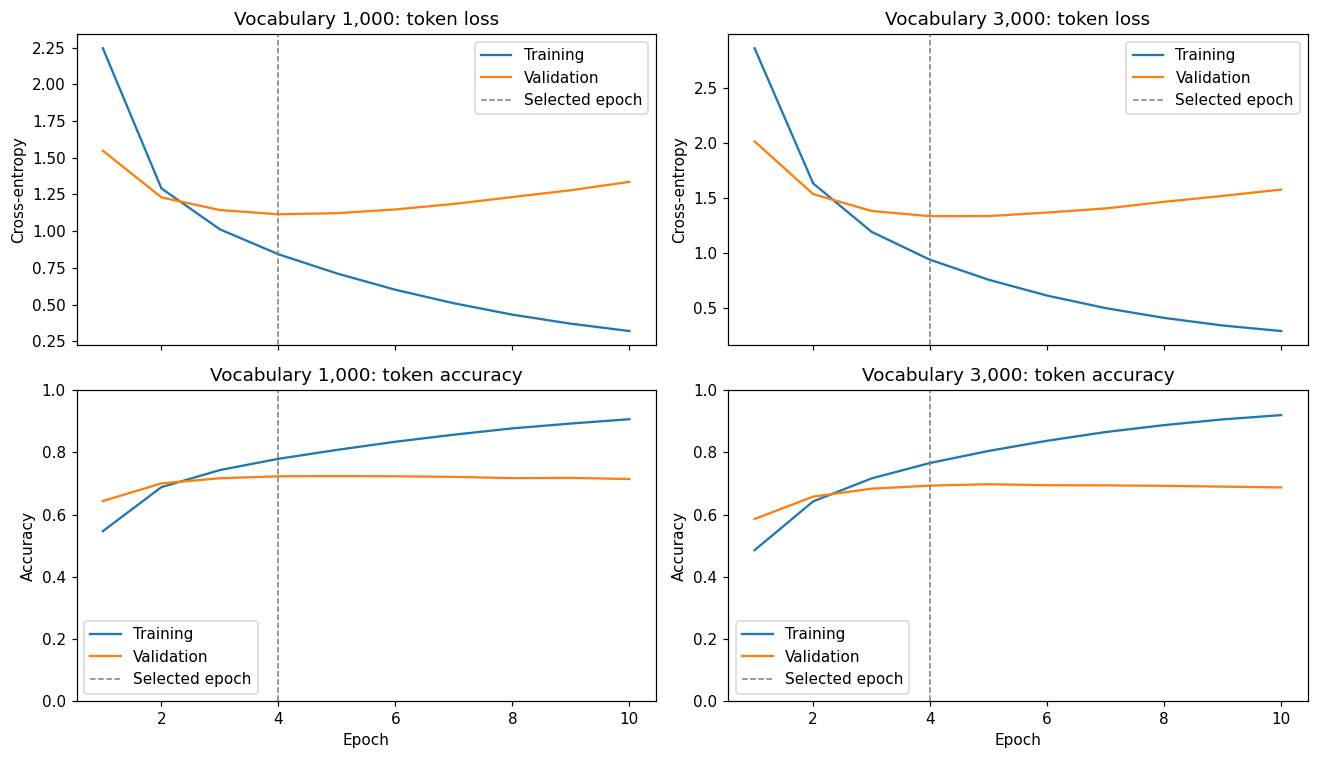

Generated wording changed on 3 of the same five inputs.
Coverage counts, complete histories, references, translations and both selected models are saved.


In [13]:
# Report percentages with their definitions, then show the same five inputs side by side.
nmt_summary_rows, nmt_coverage_rows = [], []
for nmt_result in nmt_results:
    nmt_summary_rows.append({
        "vocabulary": nmt_result["vocabulary_budget"], "selected_epoch": nmt_result["best_epoch"],
        "English validation unknown %": 100 * nmt_result["coverage"]["validation"]["english"]["unknown_rate"],
        "Spanish validation unknown %": 100 * nmt_result["coverage"]["validation"]["spanish"]["unknown_rate"],
        "validation accuracy %": 100 * nmt_result["validation_metrics"]["accuracy"],
        "accuracy with UNK as error %": 100 * nmt_result["validation_metrics"]["accuracy_unk_as_error"],
    })
    for nmt_split_name, nmt_languages in nmt_result["coverage"].items():
        for nmt_language, nmt_values in nmt_languages.items():
            nmt_coverage_rows.append({"vocabulary": nmt_result["vocabulary_budget"],
                                      "split": nmt_split_name, "language": nmt_language, **nmt_values})
nmt_summary_table = pd.DataFrame(nmt_summary_rows)
nmt_summary_table.to_csv(NMT_OUTPUT_DIR / "vocabulary_comparison.csv", index=False)
pd.DataFrame(nmt_coverage_rows).to_csv(NMT_OUTPUT_DIR / "unknown_token_counts.csv", index=False)
display(nmt_summary_table.round(2))

nmt_comparison_rows = []
for nmt_example_index, nmt_example in enumerate(nmt_five_examples):
    nmt_smaller, nmt_larger = (result["translations"][nmt_example_index] for result in nmt_results)
    assert nmt_smaller["english"] == nmt_larger["english"] == nmt_example["english"]
    assert nmt_smaller["reference"] == nmt_larger["reference"] == nmt_example["reference"]
    nmt_comparison_rows.append({"English": nmt_example["english"], "Spanish reference": nmt_example["reference"],
                                "vocabulary 1000": nmt_smaller["translation"],
                                "vocabulary 3000": nmt_larger["translation"],
                                "1000 reached EOS": nmt_smaller["ended_with_eos"],
                                "3000 reached EOS": nmt_larger["ended_with_eos"]})
nmt_comparison_table = pd.DataFrame(nmt_comparison_rows)
nmt_comparison_table.to_csv(NMT_OUTPUT_DIR / "five_translation_comparison.csv", index=False, encoding="utf-8")
with pd.option_context("display.max_colwidth", None):
    display(nmt_comparison_table[["English", "Spanish reference", "vocabulary 1000", "vocabulary 3000"]])

nmt_figure, nmt_axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for nmt_column, nmt_plot_result in enumerate(nmt_results):
    nmt_epochs = [row["epoch"] for row in nmt_plot_result["history"]]
    for nmt_curve_split, nmt_curve_label in (("train", "Training"), ("valid", "Validation")):
        nmt_axes[0, nmt_column].plot(nmt_epochs, [row[nmt_curve_split]["loss"] for row in nmt_plot_result["history"]], label=nmt_curve_label)
        nmt_axes[1, nmt_column].plot(nmt_epochs, [row[nmt_curve_split]["accuracy"] for row in nmt_plot_result["history"]], label=nmt_curve_label)
    nmt_axes[0, nmt_column].set(title=f"Vocabulary {nmt_plot_result['vocabulary_budget']:,}: token loss", ylabel="Cross-entropy")
    nmt_axes[1, nmt_column].set(title=f"Vocabulary {nmt_plot_result['vocabulary_budget']:,}: token accuracy",
                        xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
    for nmt_plot_row in (0, 1):
        nmt_axes[nmt_plot_row, nmt_column].axvline(nmt_plot_result["best_epoch"], color="grey", linestyle="--", linewidth=1,
                                  label="Selected epoch")
        nmt_axes[nmt_plot_row, nmt_column].legend()
nmt_figure.tight_layout()
save_figure(nmt_figure, "problem3_nmt_training.png")
nmt_changed_examples = sum(row["vocabulary 1000"] != row["vocabulary 3000"]
                           for row in nmt_comparison_rows)
print(f"Generated wording changed on {nmt_changed_examples} of the same five inputs.")
print("Coverage counts, complete histories, references, translations and both selected models are saved.")

### Reading the vocabulary results

Both models completed all ten epochs, and validation loss selected epoch **4** for each.<br>
Their validation loss then rises while training loss continues to fall, which indicates overfitting.<br>
I therefore use the saved epoch-4 weights for the comparison.

The main table follows the supplied notebook's unknown-token calculation, which includes punctuation.<br>
Counting words alone, with punctuation left out, English validation unknowns fall from **12.62%** to **4.73%**.<br>
Spanish validation unknown words fall from **20.37%** to **10.51%**.

The original validation token accuracy falls from **72.31%** to **69.31%**.<br>
This measure gives credit when a predicted `<unk>` matches an unknown target token.<br>
When `<unk>` is always counted as an error, accuracy instead rises from **60.77%** to **64.18%**, using the same target positions.<br>
The smaller vocabulary replaces more target words with `<unk>`, which helps explain why the two accuracy measures tell different stories.<br>
Both exclude padding and include the end marker; neither is the percentage of complete sentences translated correctly.

Increasing the vocabulary expands the word lookup tables and output layer.<br>
The model grows from **3,398,632** to **4,936,632** trainable parameters, while the embedding width, LSTM width and other training settings stay fixed.

### Translation differences

1. **“hi.”**: both models produce `<unk>.` instead of `hola.`<br>
   The larger English vocabulary recognises `hi`, while the smaller one does not.<br>
   That improvement in input coverage does not lead to a correct greeting here.
2. **“i am a good boy.”**: the smaller model gives `soy un buen <unk>.`<br>
   The larger model gives `soy un buen chico.`, which preserves the meaning of “boy”.<br>
   This is a clear improvement; its choice of `chico` is also a valid alternative to the reference's `tipo`.
3. **“may i turn on the radio?”**: both models give `¿puedo <unk> la radio?`<br>
   They retain the request for permission and the radio, but lose the action “turn on”.<br>
   Increasing the vocabulary does not improve this example.
4. **The sentence about Tom seeing Mary again**: the smaller model gives `tom está <unk> a ver a mary.`<br>
   The larger model restores useful words in `tom está deseando volver a mary a ver a mary.`<br>
   Its `deseando volver` captures more of the intended meaning, but it repeats Mary and puts the words in the wrong order.<br>
   The reference is `tom está deseando volver a ver a mary.`
5. **The long sentence about remembering someone from the past**: both models lose the contrast between the person today and the person remembered.<br>
   The smaller model repeats incomplete phrases; the larger model also produces an unfaithful sentence.<br>
   Both still have `occasionally` as an unknown English token.<br>
   The larger vocabulary does not solve this longer sentence.

The larger vocabulary improves coverage and helps some words and phrases, but the translation results are mixed.<br>
It does not resolve every missing word, repetition or change of meaning.<br>
All ten outputs reached their end marker, which shows that generation stopped, not that the translations were correct.<br>
These five fixed examples illustrate particular successes and errors; they do not establish overall sentence accuracy.

## Sources

The assignment, lecture slides and supplied RNN, LSTM and `3_NMT.ipynb` notebooks guided these solutions for me.<br><br>
The stock-price snapshot comes from [Yahoo Finance](https://finance.yahoo.com/quote/MSFT/history/).<br>
The parallel sentences come from [Tatoeba through ManyThings](https://www.manythings.org/anki/), using the archive and attribution recorded in Problem 3.<br>
[PyTorch's RNN and LSTM documentation](https://docs.pytorch.org/docs/stable/nn.html#recurrent-layers) describes the recurrent layers used here.<br>
[MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html) describes the fitted price transformation.<br>
The [Nasdaq trading calendar](https://nasdaqtrader.com/Trader.aspx?id=Calendar) lists the September 7th market holiday.